# Firing-rate check: online control experiment

This notebook compares motoneuron firing-rate distributions between experimental
recordings and simulations of the motoneuron pool driven by the recorded force.

**Pipeline:**
1. Scale each experimental force trace to a target drive amplitude and record the
   scaling in a manifest.
2. Run the motoneuron pool on the scaled force (Julia, section 4).
3. Compute firing rates from experimental and simulated spike trains with the same
   estimator, and compare the distributions day by day.

**Data:**
- Experimental: one `.pkl` per trial, containing the spike trains (`MU`), the force
  signal (`Force`), the task-controlled MU pair (`Idx_MU_Pair`) and the sampling rate
  (`fsamp`).
- Simulated: one `.jld2` per trial, containing the pool spike raster (`spike_array`)
  and its sampling rate (`fs`).

**Supporting modules:**
- `utils/functions_analysis_online_control_exp/unified_pipeline.py` — force scaling,
  the manifest, and the firing-rate estimator.
- `utils/functions_run_simulations/run_from_manifest.jl` — the simulation driver.

Force serves as the model input as a proxy for the common synaptic drive, in
arbitrary units, so it has to be scaled before it means anything to the pool. Scaling
and rate estimation are each defined once and applied to both sides, so that any
difference between the distributions reflects the model rather than the analysis.

---

## 1. Environment setup

### 1.1 Package imports

In [1]:
import os, sys, re, glob, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# --- repo root on the path (this notebook lives in notebooks/) ---------------
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from utils.functions_analysis_online_control_exp import unified_pipeline as up
from utils.functions_analysis_online_control_exp import firing_rate_checks as fr

print("repo root :", ROOT)
print("SIM_FS_HZ :", up.SIM_FS_HZ, "Hz   <- spike_array is on the 0.05 ms integration grid")

repo root : /Users/nmt121/Desktop/Repositories/Motoneuron_Model
SIM_FS_HZ : 20000.0 Hz   <- spike_array is on the 0.05 ms integration grid


### 1.2 Plot style


In [2]:
# Categorical colours, assigned by entity: blue = experimental, orange = simulated.
C_EXP, C_SIM, C_ALT = fr.C_EXP, fr.C_SIM, fr.C_ALT
INK, INK2, GRID     = fr.INK, fr.INK2, fr.GRID

fr.apply_plot_style()
tidy = fr.tidy        # recessive grid helper, used by every figure below

### 1.3 Configuration

Paths and analysis parameters are set here and used throughout.

`REPRESENTATIVE` maps each day to a single trial, chosen on duration and smoothness by
`choose_representative_force_trial.duration_vs_smoothness_scatter_with_median`. Pass
`trials=None` in section 3 to scale every trial instead.

Experimental recordings are located via `MN_DATA_ROOT`, falling back to `<repo>/data`
and `~/Desktop/DATA`. `SIM_ROOT` is where section 4 writes its spike files and where
sections 5 and 8 read them from.

In [3]:
from functools import partial

SUBJECT = "S1"

EXP_DIR = fr.find_data_root(SUBJECT, ROOT) / SUBJECT   # raw .pkl recordings
DATA    = ROOT / "Data_MN_Model" / "Data_final"

# One representative trial per day (day -> trial number).
REPRESENTATIVE = {1: 21, 3: 11, 4: 9, 5: 18, 6: 5, 7: 19, 8: 23,
                  9: 9, 10: 15, 11: 8, 12: 25, 13: 9, 14: 28}

# --- firing-rate estimator settings ----------------------------------------
MAX_ISI    = 0.2    # s. Discard ISIs above this before averaging (see 1.2).
MIN_SPIKES = 5      # units with fewer spikes are flagged, not silently dropped.
MIN_DUTY   = 0.0    # fraction of the trial a unit must span. 0 = no constraint.
FR_CAP     = 80.0   # Hz

# --- scaling ----------------------------------------------------------------
POLICY   = "per_trial_max"   # 'global_max' | 'per_trial_max' | 'per_trial_mean'
TARGET   = 0.4            # drive amplitude that recruits the full pool
SCALED_DIR = DATA / "Scaled_force" / f"{SUBJECT}_{POLICY}"
SIM_ROOT   = DATA / "Spikes" / f"{SUBJECT}_{POLICY}"

# --- rate traces over time (section 8) --------------------------------------
SMOOTH_S = 0.4      # Hanning window applied to the spike train (s)
RATE_FS  = 100.0    # sampling rate of the smoothed traces (Hz)

# Bind the helpers in `firing_rate_checks` to the settings above, so the rest of
# the notebook calls them without repeating the configuration each time.
load_trial_pair    = partial(fr.load_trial_pair, exp_dir=EXP_DIR, sim_root=SIM_ROOT,
                             subject=SUBJECT, min_spikes=MIN_SPIKES)
paired_rate_traces = partial(fr.paired_rate_traces, smooth_s=SMOOTH_S, rate_fs=RATE_FS)
median_rate_corr   = partial(fr.median_rate_corr, smooth_s=SMOOTH_S, rate_fs=RATE_FS)

print(f"subject {SUBJECT}: {len(list(EXP_DIR.glob('*.pkl')))} trials in {EXP_DIR}")
print(f"scaled output -> {SCALED_DIR.relative_to(ROOT)}")

subject S1: 130 trials in /Users/nmt121/Desktop/DATA/S1
scaled output -> Data_MN_Model/Data_final/Scaled_force/S1_per_trial_max


---

## 2. Firing-rate estimation

Firing rate per unit is `1 / mean(ISI)`, computed by a single function applied to both
experimental and simulated spike trains:

```python
up.firing_rates(spikes, fs, max_isi=..., min_spikes=..., min_duty=..., fr_cap=...)
```

`fs` is required rather than assumed, and is read from each file. It returns one row
per unit — including units that fail the inclusion criteria, flagged with `included`
and a `reason` — so nothing is dropped without a record.

**Inter-spike intervals longer than `MAX_ISI` are discarded before averaging.** Motor
units de-recruit during a trial. A silent gap entering the average as one long ISI
reports a low rate for a unit that was firing normally whenever it was active.
Simulated motoneurons driven above threshold do not de-recruit, so the same formula
applied to both datasets is biased downwards on the experimental side only.
Restricting to ISIs below `MAX_ISI` gives the rate while the unit was active, which is
the quantity that is comparable between the two.



In [4]:
# Same data, same inclusion criteria -- the ONLY difference is max_isi.
exp_active  = fr.exp_rates_per_day(EXP_DIR, max_isi=MAX_ISI,
                                   min_spikes=MIN_SPIKES, min_duty=MIN_DUTY, fr_cap=FR_CAP)
exp_all_isi = fr.exp_rates_per_day(EXP_DIR, max_isi=None,
                                   min_spikes=MIN_SPIKES, min_duty=MIN_DUTY, fr_cap=FR_CAP)

print(f"{len(exp_active)} units across {exp_active.day.nunique()} days "
      f"({exp_active.included.sum()} included)")

1881 units across 13 days (1805 included)


In [5]:
a = exp_all_isi.loc[exp_all_isi.included, "rate_hz"].to_numpy()   # 1/mean(all ISIs)
b = exp_active.loc[exp_active.included,  "rate_hz"].to_numpy()    # ISIs > 200 ms dropped

summary = pd.DataFrame({
    "all ISIs": [np.percentile(a, 10), np.median(a), np.percentile(a, 90)],
    f"ISI <= {MAX_ISI} s": [np.percentile(b, 10), np.median(b), np.percentile(b, 90)],
}, index=["p10", "median", "p90"]).round(2)
summary["shift"] = (summary.iloc[:, 1] - summary.iloc[:, 0]).round(2)
display(summary)

drop = exp_active.loc[exp_active.included, "isi_dropped_frac"]
print(f"\nISIs discarded as de-recruitment gaps: median {100*drop.median():.1f}% of a unit's ISIs")
print(f"units losing >5% of their ISIs to silence: {(drop > 0.05).mean()*100:.0f}%")

,all ISIs,ISI <= 0.2 s,shift
p10,6.32,9.63,3.31
median,10.24,11.47,1.23
p90,12.89,13.69,0.80



ISIs discarded as de-recruitment gaps: median 2.4% of a unit's ISIs
units losing >5% of their ISIs to silence: 32%


The median moves by about 1.3 Hz, but the 10th percentile moves by over 3 Hz: the low
shoulder of the experimental distribution consists largely of de-recruitment gaps
rather than slow firing. The model cannot produce that shoulder, so leaving it in would
separate the two distributions for a reason unrelated to the model.

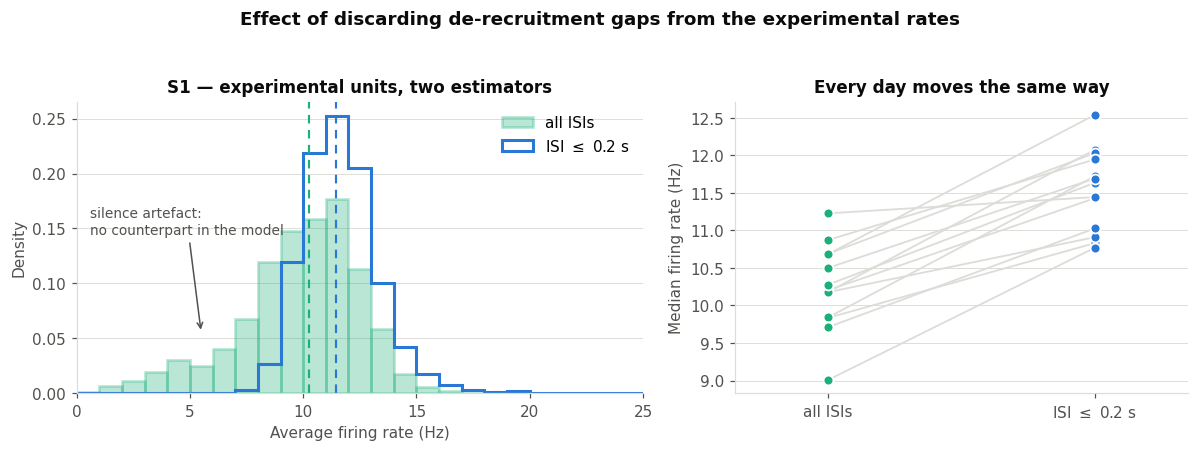

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.9),
                               gridspec_kw={"width_ratios": [1.25, 1]})

# --- left: pooled distributions, both estimators --------------------------
bins = np.arange(0, 26, 1.0)
ax1.hist(a, bins=bins, density=True, color=C_ALT, alpha=0.30,
         edgecolor=C_ALT, linewidth=1.8, label="all ISIs")
ax1.hist(b, bins=bins, density=True, histtype="step",
         edgecolor=C_EXP, linewidth=2.0, label=f"ISI $\\leq$ {MAX_ISI} s")
for v, c in [(np.median(a), C_ALT), (np.median(b), C_EXP)]:
    ax1.axvline(v, color=c, linestyle=(0, (4, 3)), linewidth=1.4)
ax1.annotate("silence artefact:\nno counterpart in the model",
             xy=(5.5, 0.055), xytext=(0.6, 0.145), color=INK2, fontsize=9,
             arrowprops=dict(arrowstyle="->", color=INK2, linewidth=1))
ax1.set_xlabel("Average firing rate (Hz)"); ax1.set_ylabel("Density")
ax1.set_title(f"{SUBJECT} — experimental units, two estimators")
ax1.set_xlim(0, 25); ax1.legend(loc="upper right"); tidy(ax1)

# --- right: per-day medians, paired ---------------------------------------
med_all = exp_all_isi[exp_all_isi.included].groupby("day").rate_hz.median()
med_active = exp_active[exp_active.included].groupby("day").rate_hz.median()
days = med_all.index.to_numpy()
for d in days:
    ax2.plot([0, 1], [med_all[d], med_active[d]], color=GRID, linewidth=1.2, zorder=1)
ax2.scatter(np.zeros_like(days), med_all.values, s=42, color=C_ALT, zorder=3,
            label="all ISIs", edgecolor="white", linewidth=1.2)
ax2.scatter(np.ones_like(days), med_active.values, s=42, color=C_EXP, zorder=3,
            label="active only", edgecolor="white", linewidth=1.2)
ax2.set_xticks([0, 1]); ax2.set_xticklabels(["all ISIs", f"ISI $\\leq$ {MAX_ISI} s"])
ax2.set_xlim(-0.35, 1.35); ax2.set_ylabel("Median firing rate (Hz)")
ax2.set_title("Every day moves the same way"); tidy(ax2)
# the x tick labels already name the two groups -- a legend would repeat them

fig.suptitle("Effect of discarding de-recruitment gaps from the experimental rates",
             fontsize=12, fontweight="semibold", y=1.04, color=INK)
plt.tight_layout(); plt.show()

---

## 3. Force scaling

Force is recorded in arbitrary units. What matters to the pool is where the scaled
trace sits relative to the motoneurons' recruitment thresholds, so the target amplitude
has to be chosen against those thresholds rather than picked.

`up.scale_forces` offers three policies:

| policy | normalises | consequence |
|---|---|---|
| `global_max` | one factor for the whole set, so the largest peak equals `target` | preserves relative amplitude across days and trials; only the largest trial reaches full recruitment |
| `per_trial_max` | each trial's own peak to `target` | identical maximum recruitment on every trial; amplitude differences are discarded |
| `per_trial_mean` | each trial's own mean to `target` | fixes the mean and leaves the peak free |

`remove_baseline` subtracts each trace's minimum before scaling, and is recorded either
way.

Section 3.1 measures where the thresholds are; 3.2 shows what each policy delivers
against them.

### 3.1 Recruitment thresholds of the pool

Driving each motoneuron with a constant input and sweeping its amplitude gives the
recruitment threshold and the firing rate immediately above it. This is a property of
the model, independent of any recording, and it sets the amplitude the scaling has to
deliver.

Produced by `scripts` equivalent to:

```julia
build_pool(".../VthCa_TA_subject1_gamma1.jld2")
global tspan = 0:0.05:3000
st = (0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,-1.0,-1.0,0,0)
for i in 1:nr_s, a in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.60]
    _vd, vs, _, _p, _m, _h, _n, _q = ode4(tspan, 0., 0., i, st, fill(a,3000), fill(1e-5a,3000), MNs)
    # spikes_from_aps(vs, i, MNs) -> rate at this drive
end
```

and saved to `Data_MN_Model/Data_final/pool_fI_curve.csv`.

The drive is swept on a coarse grid, so a threshold is reported as the lowest swept
amplitude at which a unit fires. The steps in the right-hand panel below are that grid,
not five threshold classes in the pool — the true thresholds are distributed
continuously within each step. The grid is fine enough for choosing a target amplitude,
which is what it is used for; refine `amps` if the threshold distribution itself is the
question.

In [7]:
FI_PATH = DATA / "pool_fI_curve.csv"

if not FI_PATH.exists():
    print(f"{FI_PATH.relative_to(ROOT)} not found -- run the f-I sweep above.")
    fi = thresholds = None
else:
    fi = pd.read_csv(FI_PATH)
    # recruitment threshold = lowest swept drive at which the neuron fires
    fired = fi[fi.n_spikes > 0]
    thresholds = fired.groupby("neuron").drive.min().rename("threshold")
    silent = sorted(set(fi.neuron) - set(thresholds.index))

    print(f"pool of {fi.neuron.nunique()} motoneurons, drive swept "
          f"{fi.drive.min():.2f}-{fi.drive.max():.2f}")
    print(f"recruitment threshold: {thresholds.min():.2f} (first unit) .. "
          f"{thresholds.max():.2f} (last unit)")
    if silent:
        print(f"  {len(silent)} unit(s) silent across the whole sweep")

    at_thr = (fired.merge(thresholds, on="neuron")
                   .query("drive == threshold").rate_hz)
    print(f"firing rate on recruitment: median {at_thr.median():.1f} Hz "
          f"({at_thr.min():.1f}-{at_thr.max():.1f})")
    print(f"\nfraction of the pool recruited at a given drive:")
    for a in sorted(fi.drive.unique()):
        print(f"  {a:.2f} -> {(thresholds <= a).mean()*100:5.1f}%")

pool of 181 motoneurons, drive swept 0.10-0.60
recruitment threshold: 0.20 (first unit) .. 0.40 (last unit)
firing rate on recruitment: median 13.3 Hz (8.7-19.3)

fraction of the pool recruited at a given drive:
  0.10 ->   0.0%
  0.15 ->   0.0%
  0.20 ->  22.1%
  0.25 ->  49.7%
  0.30 ->  74.0%
  0.35 ->  97.8%
  0.40 -> 100.0%
  0.50 -> 100.0%
  0.60 -> 100.0%


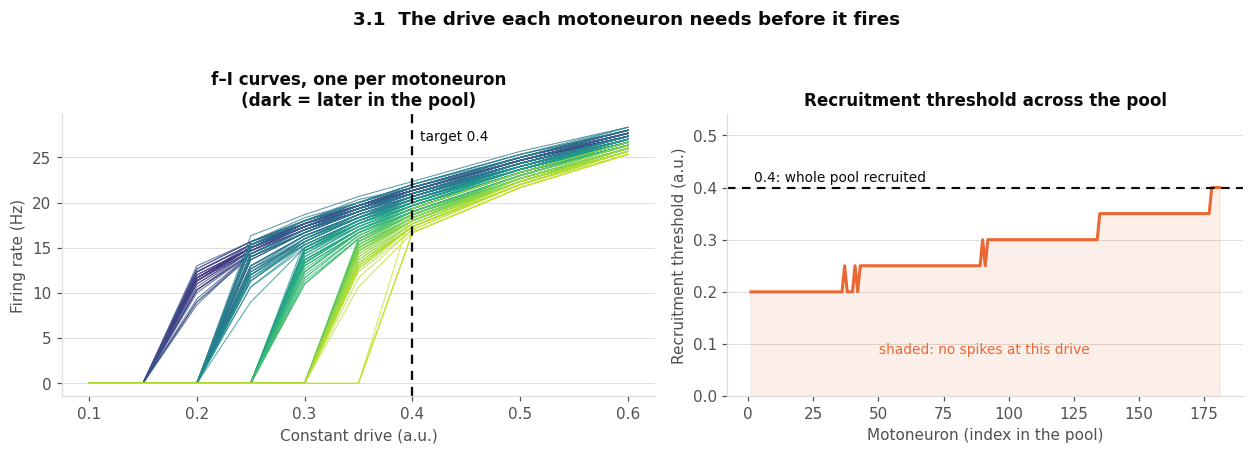

In [8]:
if fi is not None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.0),
                                   gridspec_kw={"width_ratios": [1.15, 1]})

    # --- f-I curves, one per motoneuron, shaded by position in the pool -----
    n_mn = fi.neuron.nunique()
    ramp = plt.cm.viridis(np.linspace(0.08, 0.92, n_mn))
    for u, gg in fi.groupby("neuron"):
        ax1.plot(gg.drive, gg.rate_hz, color=ramp[u - 1], linewidth=0.7, alpha=0.75)
    ax1.axvline(TARGET, color=INK, linestyle=(0, (4, 3)), linewidth=1.5)
    ax1.annotate(f"target {TARGET}", xy=(TARGET, ax1.get_ylim()[1]),
                 xytext=(5, -10), textcoords="offset points",
                 fontsize=9, color=INK, ha="left", va="top")
    ax1.set_xlabel("Constant drive (a.u.)")
    ax1.set_ylabel("Firing rate (Hz)")
    ax1.set_title("f–I curves, one per motoneuron\n(dark = later in the pool)")
    tidy(ax1)

    # --- recruitment threshold across the pool ------------------------------
    ax2.plot(thresholds.index, thresholds.values, color=C_SIM, linewidth=2.0)
    ax2.fill_between(thresholds.index, 0, thresholds.values, color=C_SIM, alpha=0.10)
    ax2.axhline(TARGET, color=INK, linestyle=(0, (4, 3)), linewidth=1.4)
    ax2.annotate(f"{TARGET}: whole pool recruited", xy=(0, TARGET),
                 xytext=(4, 4), textcoords="offset points", fontsize=9, color=INK)
    ax2.text(n_mn * 0.5, thresholds.min() * 0.45, "shaded: no spikes at this drive",
             fontsize=9, color=C_SIM, ha="center", va="center")
    ax2.set_xlabel("Motoneuron (index in the pool)")
    ax2.set_ylabel("Recruitment threshold (a.u.)")
    ax2.set_title("Recruitment threshold across the pool")
    ax2.set_ylim(0, max(TARGET * 1.35, thresholds.max() * 1.15))
    tidy(ax2)

    fig.suptitle("3.1  The drive each motoneuron needs before it fires",
                 fontsize=12, fontweight="semibold", y=1.02, color=INK)
    plt.tight_layout(); plt.show()

### 3.2 What each policy delivers

In [9]:
peaks = fr.dry_run_policies(SUBJECT, EXP_DIR, REPRESENTATIVE,
                         [("global_max", 0.4), ("per_trial_max", 0.4), ("per_trial_mean", 0.3)])
peaks["ratio mean/global"] = (peaks.iloc[:, 2] / peaks.iloc[:, 0])
display(peaks.round(3))

print(f"\nPeak drive delivered, across the same 13 trials:")
for col in peaks.columns[:3]:
    print(f"  {col:26s}  {peaks[col].min():.3f} .. {peaks[col].max():.3f}")
print(f"\nSame trial, different policy: up to {peaks['ratio mean/global'].max():.1f}x "
      f"difference in drive.")

,global_max -> 0.4,per_trial_max -> 0.4,per_trial_mean -> 0.3,ratio mean/global
day,,,,
1,0.241,0.4,0.579,2.404
3,0.400,0.4,0.813,2.032
4,0.185,0.4,0.607,3.283
5,0.173,0.4,0.439,2.538
6,0.137,0.4,0.582,4.242
7,0.297,0.4,0.678,2.279
8,0.191,0.4,0.664,3.476
9,0.161,0.4,0.769,4.767
10,0.276,0.4,0.634,2.295



Peak drive delivered, across the same 13 trials:
  global_max -> 0.4           0.137 .. 0.400
  per_trial_max -> 0.4        0.400 .. 0.400
  per_trial_mean -> 0.3       0.439 .. 0.813

Same trial, different policy: up to 4.8x difference in drive.


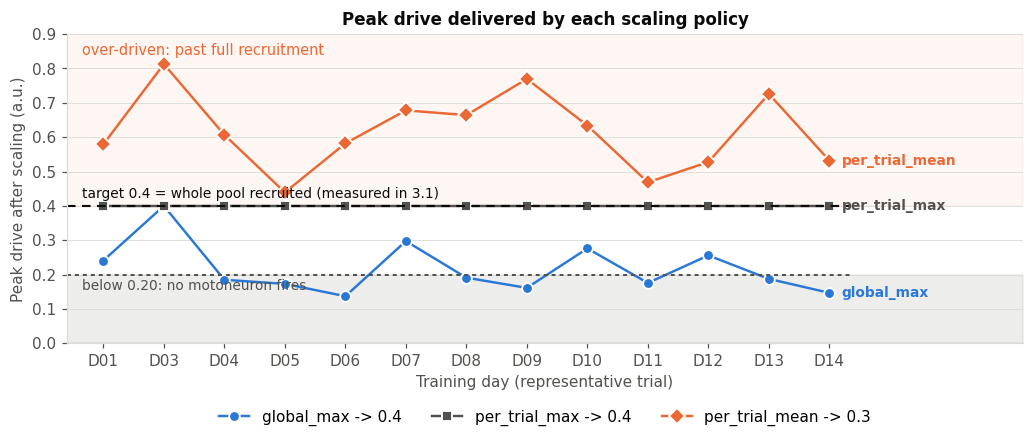

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
cols = list(peaks.columns[:3])
colors = [C_EXP, INK2, C_SIM]
markers = ["o", "s", "D"]
x = np.arange(len(peaks))

for col, c, mk in zip(cols, colors, markers):
    ax.plot(x, peaks[col].values, marker=mk, markersize=7, linewidth=1.6,
            color=c, label=col, markeredgecolor="white", markeredgewidth=1.2)

# Bands mark the recruitment range measured in 3.1: below the first threshold
# the pool is silent; above the target it is fully recruited and climbing the
# steep part of the f-I curves.
ax.fill_between([-0.6, len(peaks) + 2.2], TARGET, 0.9, color=C_SIM, alpha=0.06, zorder=0)
if fi is not None:
    thr_lo = float(thresholds.min())
    ax.fill_between([-0.6, len(peaks) + 2.2], 0, thr_lo, color=INK2, alpha=0.10, zorder=0)
    ax.plot([-0.6, x[-1] + 0.35], [thr_lo, thr_lo], color=INK2,
            linestyle=(0, (2, 2)), linewidth=1.3, zorder=2)
    ax.text(-0.35, thr_lo - 0.012, f"below {thr_lo:.2f}: no motoneuron fires",
            color=INK2, fontsize=9, va="top", ha="left")
# Stop the target line at the data, so it does not run under the right-hand
# direct labels.
ax.plot([-0.6, x[-1] + 0.35], [TARGET, TARGET], color=INK,
        linestyle=(0, (4, 3)), linewidth=1.4, zorder=2)
ax.text(-0.35, 0.875, "over-driven: past full recruitment",
        color=C_SIM, fontsize=9.5, va="top", ha="left")
ax.text(-0.35, 0.415, f"target {TARGET} = whole pool recruited (measured in 3.1)",
        color=INK, fontsize=9, va="bottom", ha="left")

# Direct labels at the right end -- identity never rests on colour alone.
for col, c in zip(cols, colors):
    ax.annotate(col.split(" ->")[0], xy=(x[-1], peaks[col].values[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", ha="left",
                fontsize=9, color=c, fontweight="semibold")

ax.set_xticks(x); ax.set_xticklabels([f"D{d:02d}" for d in peaks.index])
ax.set_xlim(-0.6, len(peaks) + 2.2); ax.set_ylim(0, 0.9)
ax.set_xlabel("Training day (representative trial)")
ax.set_ylabel("Peak drive after scaling (a.u.)")
ax.set_title("Peak drive delivered by each scaling policy")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3); tidy(ax)
plt.tight_layout(); plt.show()

The measurement settles the choice of policy for this dataset.

On the swept grid the first motoneuron is recruited at a drive of 0.20 and the whole
pool by 0.40, so 0.4 is the amplitude that engages every unit — the value the earlier
code used, now measured rather than assumed. Recruitment is steep in between: 22% of the
pool at 0.20, 50% at 0.25, 74% at 0.30, 98% at 0.35.

Raw peak force varies about 2.9× across days, wider than the interval between first and
full recruitment. **No single global factor can place every day inside it:** `global_max`
puts eleven of thirteen days below 0.25 and Day 06 and Day 14 below 0.15, under the first
neuron's threshold, where the pool is silent and there is nothing to compare against.
That is not hypothetical — running the sweep under `global_max` returned a Day 06 raster
with zero spikes.

`per_trial_max` is therefore the policy used here. Every trial reaches full recruitment
and every trial produces spikes, at the cost of discarding between-day amplitude
differences — differences that are in arbitrary units and reflect gain and electrode
placement as much as drive.

`per_trial_mean` fixes the mean and leaves the peak uncontrolled, landing between 0.44
and 0.81, past full recruitment and into the steep part of the f–I curves.

`POLICY` in section 1.3 selects the one used for the rest of the notebook.

One consequence to carry forward: units enter at a median of 13.3 Hz (range 8.7–19.3),
so the model has a minimum sustained rate close to the *centre* of the experimental
distribution rather than its low end. It has no slow-firing regime near threshold: a unit
is either off or already firing at ~13 Hz. That is the f–I floor referred to in section 9,
and it is a property of the model, not of the scaling.

### 3.3 Scale and save

`scale_forces` writes one `.npy` per trial plus a `manifest.csv` recording, for each
trial, the source file, the policy, whether the baseline was removed, the scale factor,
and the resulting min/mean/max. The manifest is what the simulation step reads, so the
amplitude is fixed here and is not recomputed downstream.

In [11]:
manifest = up.scale_forces(
    subject   = SUBJECT,
    src_dir   = str(EXP_DIR),
    out_dir   = str(SCALED_DIR),
    policy    = POLICY,        # 'global_max' -- preserves relative amplitude
    target    = TARGET,
    remove_baseline = True,    # recorded either way
    trials    = REPRESENTATIVE,  # None -> every trial in the folder
    overwrite = True,
)

display(manifest[["day", "trial", "policy", "target", "scale_factor",
                  "raw_max", "out_max", "out_mean", "fs", "duration_s"]].head(6).round(4))

[S1] wrote 13 scaled traces + manifest -> /Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S1_per_trial_max/manifest.csv
[S1] resulting peak drive: min=0.400 median=0.400 max=0.400


,day,trial,policy,target,scale_factor,raw_max,out_max,out_mean,fs,duration_s
0,1,21,per_trial_max,0.4,2.8578,0.1469,0.4,0.2072,2048.0,21.125
1,3,11,per_trial_max,0.4,1.7214,0.2424,0.4,0.1477,2048.0,21.250
2,4,9,per_trial_max,0.4,3.7247,0.1173,0.4,0.1978,2048.0,7.875
3,5,18,per_trial_max,0.4,3.9772,0.1017,0.4,0.2731,2048.0,6.000
4,6,5,per_trial_max,0.4,5.0198,0.0751,0.4,0.2062,2048.0,8.750
5,7,19,per_trial_max,0.4,2.3146,0.1749,0.4,0.1770,2048.0,10.750


### 3.4 Verify the manifest

`verify_manifest` re-reads every `.npy` and checks its length and peak against the
recorded row. Run it after scaling and before starting a simulation sweep.

In [12]:
problems = up.verify_manifest(manifest)
if len(problems) == 0:
    print(f"OK — all {len(manifest)} files on disk match their manifest rows.")
else:
    print(f"{len(problems)} PROBLEM(S):")
    display(problems[["day", "trial", "out_file", "problem"]])

OK — all 13 files on disk match their manifest rows.


---

## 4. Run the simulations *(Julia)*

This step runs in a Julia kernel rather than here. From the repository root:

```julia
# `using` first -- creation_model.jl needs @unpack at include time.
using NPZ, Interpolations, Distributions, Random, JLD2, Printf, Statistics
using Parameters, DSP, SymDict, Match, CSV, DataFrames

folder = "utils/functions_run_simulations/"
for f in sort(readdir(folder))
    endswith(f, ".jl") && include(joinpath(folder, f))
end

MNs, nr_s = build_pool("Data_MN_Model/Data_final/Subjects_optim_process/VthCa_TA_subject1_gamma1.jld2")

run_manifest("Data_MN_Model/Data_final/Scaled_force/S1_global_max/manifest.csv",
             "Data_MN_Model/Data_final/Spikes/S1_global_max";
             extra_gain = 1.0)
```

`build_pool` constructs the motoneuron pool and installs it, along with the model
constants, as the globals the ODE code reads. It takes a `seed` so that the rheobase
jitter is reproducible between runs.

`run_manifest` iterates over the manifest rows, resamples each scaled trace to the
1 kHz grid the integrator expects, runs the pool, and writes one `.jld2` per trial:

| field | contents |
|---|---|
| `spike_array` | pool spike raster, `(nr_s, n_samples)` |
| `fs` | its sampling rate in Hz |
| `force_file`, `policy`, `scale_factor`, `gain` | provenance from the manifest row |
| `subject`, `day`, `trial` | identifiers |

`ode4` integrates at a fixed step of 0.05 ms, so `spike_array` sits on a 20 kHz grid.
The rate is stored in each file rather than assumed by whatever reads it.

`extra_gain` multiplies the scaled force and defaults to 1.0. It is written into the
output, so any gain applied beyond the manifest amplitude remains visible in the
analysis.

---

## 5. Compute firing rates

### 5.1 From simulated spike rasters

The estimator from section 2, applied to the simulated spike arrays with `fs` read from
each file. `up.included_rates(df)` returns the rates of the units that passed.

In [13]:
sim_new = fr.load_sim_rates(SIM_ROOT, SUBJECT, max_isi=MAX_ISI,
                         min_spikes=MIN_SPIKES, min_duty=MIN_DUTY, fr_cap=FR_CAP)

if sim_new is None:
    print(f"No new-style simulations yet under {SIM_ROOT.relative_to(ROOT)}")
    print("-> run section 4 in Julia, then re-run this cell.")
else:
    print(f"{len(sim_new)} simulated units over {sim_new.day.nunique()} days "
          f"(fs read from file: {sorted(sim_new.fs.unique())})")

2353 simulated units over 13 days (fs read from file: [20000.0])


### 5.2 Pre-computed rate files

Earlier runs saved firing-rate vectors directly, without keeping the spike arrays.
Those files are loaded here so section 6 produces a comparison before the sweep in
section 4 has been run. They were computed over all ISIs, so section 6 matches the
experimental estimator to them whenever they are the source in use.

In [14]:
sim_precomputed = fr.load_precomputed_rates(DATA, SUBJECT)
if sim_precomputed:
    warnings.warn("Using pre-computed simulated rates (all ISIs, gain not "
                  "recorded). Run section 4 to replace them.", stacklevel=2)
    print(f"pre-computed rates for days: {list(sim_precomputed)}")
    print(f"units per day: {[len(v) for v in sim_precomputed.values()]}")
else:
    print("no pre-computed rate files found")

pre-computed rates for days: [1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
units per day: [181, 181, 181, 165, 162, 181, 181, 168, 181, 181, 181, 181, 181]


/Users/nmt121/miniconda3/envs/neuromotor/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3701: UserWarning: Using pre-computed simulated rates (all ISIs, gain not recorded). Run section 4 to replace them.
  exec(code_obj, self.user_global_ns, self.user_ns)


---

## 6. Compare distributions

Experimental and simulated rate distributions, per day. The comparison uses the
spike-derived rates from section 5.1 when they exist and the pre-computed vectors
otherwise, matching the experimental estimator to whichever is in use.

In [15]:
# Use spike-derived rates when available, otherwise the pre-computed vectors.
if sim_new is not None:
    sim_by_day = {d: up.included_rates(g) for d, g in sim_new.groupby("day")}
    sim_label, sim_is_precomputed = "Simulated", False
else:
    sim_by_day = sim_precomputed
    sim_label, sim_is_precomputed = "Simulated (pre-computed)", True

# Match the experimental estimator to whichever simulated source is in use.
exp_src = exp_all_isi if sim_is_precomputed else exp_active
exp_by_day = {d: up.included_rates(g) for d, g in exp_src.groupby("day")}

rows = []
for d in sorted(set(exp_by_day) & set(sim_by_day)):
    e, s = exp_by_day[d], sim_by_day[d]
    if e.size == 0 or s.size == 0:
        continue
    rows.append({"day": d, "n_exp": e.size, "exp_p10": np.percentile(e, 10),
                 "exp_med": np.median(e), "exp_p90": np.percentile(e, 90),
                 "n_sim": s.size, "sim_p10": np.percentile(s, 10),
                 "sim_med": np.median(s), "sim_p90": np.percentile(s, 90),
                 "d_median": np.median(s) - np.median(e)})
comp = pd.DataFrame(rows).set_index("day").round(2)

print(f"Experimental estimator: max_isi={'all ISIs' if sim_is_precomputed else MAX_ISI}")
print(f"Simulated source      : {sim_label}\n")
display(comp)
print(f"\nMean shift in median: {comp.d_median.mean():+.2f} Hz "
      f"(range {comp.d_median.min():+.2f} .. {comp.d_median.max():+.2f})")

Experimental estimator: max_isi=0.2
Simulated source      : Simulated



,n_exp,exp_p10,exp_med,exp_p90,n_sim,sim_p10,sim_med,sim_p90,d_median
day,,,,,,,,,
1,140,9.68,10.83,12.80,181,12.83,14.09,14.85,3.26
3,110,10.28,11.72,12.76,177,11.67,14.90,16.60,3.18
4,153,10.16,12.08,13.95,181,13.97,14.91,16.09,2.83
5,137,9.98,11.43,12.69,181,15.53,17.58,18.82,6.15
6,111,8.74,10.91,12.78,181,13.36,14.46,15.29,3.55
7,170,10.34,12.54,15.19,181,11.64,15.05,16.65,2.51
8,126,10.03,11.64,13.80,181,12.24,15.23,16.06,3.59
9,158,9.20,11.03,13.30,181,11.84,16.17,17.22,5.14
10,160,10.16,12.03,14.70,177,11.34,14.18,15.32,2.15



Mean shift in median: +3.51 Hz (range +2.15 .. +6.15)


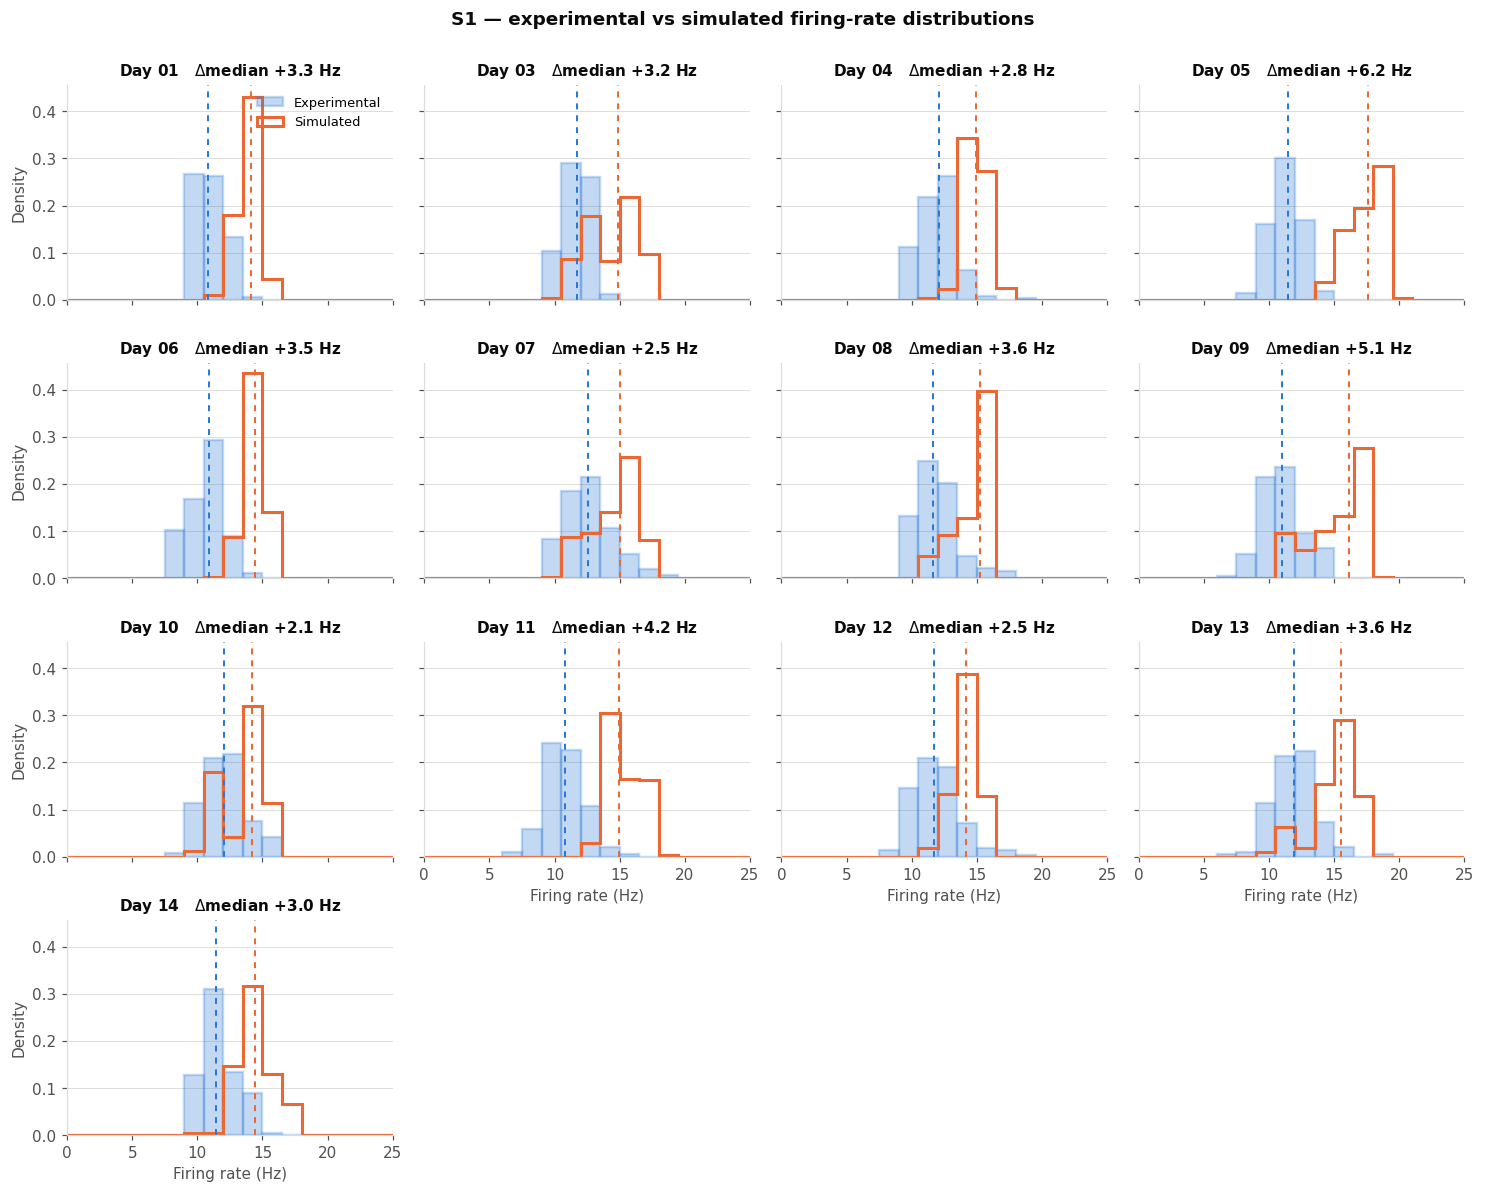

In [16]:
days = list(comp.index)
ncol = 4
nrow = int(np.ceil(len(days) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 2.7 * nrow),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()
bins = np.arange(0, 26, 1.5)

for ax, d in zip(axes, days):
    e, s = exp_by_day[d], sim_by_day[d]
    ax.hist(e, bins=bins, density=True, color=C_EXP, alpha=0.28,
            edgecolor=C_EXP, linewidth=1.6, label="Experimental")
    ax.hist(s, bins=bins, density=True, histtype="step",
            edgecolor=C_SIM, linewidth=2.0, label=sim_label)
    ax.axvline(np.median(e), color=C_EXP, linestyle=(0, (3, 3)), linewidth=1.3)
    ax.axvline(np.median(s), color=C_SIM, linestyle=(0, (3, 3)), linewidth=1.3)
    ax.set_title(f"Day {d:02d}   $\\Delta$median {comp.loc[d,'d_median']:+.1f} Hz",
                 fontsize=10)
    ax.set_xlim(0, 25); tidy(ax)

for ax in axes[len(days):]:
    fig.delaxes(ax)

# With 13 days in a 4-column grid the last row is partly empty, so
# "is_last_row" would label only Day 14.  Label the lowest surviving axis in
# each column instead, and force its tick labels back on (sharex hides them).
bottom_of_col = {}
for i in range(len(days)):
    bottom_of_col[i % ncol] = i
for i in bottom_of_col.values():
    axes[i].set_xlabel("Firing rate (Hz)")
    axes[i].tick_params(labelbottom=True)
for i in range(len(days)):
    if i % ncol == 0:
        axes[i].set_ylabel("Density")

axes[0].legend(loc="upper right", fontsize=8.5)
fig.suptitle(f"{SUBJECT} — experimental vs simulated firing-rate distributions",
             fontsize=12, fontweight="semibold", y=1.0, color=INK)
plt.tight_layout(); plt.show()

---

## 7. Firing rate over time

Section 6 compares the *distribution* of average rates, which says nothing about when
units fire. This section compares discharge as a function of time, which is what shows
whether the model reproduces the features that characterise a motoneuron pool driven
by a common input: recruitment in order of threshold, rate modulation following the
drive, and de-recruitment as the drive falls.

**Pairing units.** The pool contains 181 motoneurons; decomposition recovers 11–17 per
trial. Plotting the whole pool against a dozen recorded units would not be a
comparison, so `up.match_units_by_recruitment` pairs each experimental unit with the
simulated unit whose first spike is closest in time, greedily and without replacement.
Recruitment time is therefore the basis of the pairing, which leaves rate modulation
and de-recruitment free to agree or disagree — those are what the figure tests.

**Rates over time** come from `up.smoothed_rate`, a normalised 400 ms Hanning window
applied to the spike train, matching `conv_spikes_rates.jl`.

This notebook covers the online control recordings. The equivalent comparison against
the data used for parameter tuning belongs with `optimization_vthca_values.ipynb`,
which is where those traces live.

In [17]:
available = sorted(
    (int(re.search(r"Day(\d+)", p).group(1)), int(re.search(r"trial(\d+)", p).group(1)))
    for p in glob.glob(str(SIM_ROOT / "Day*" / "*.jld2")))
print(f"simulated trials available: {len(available)}")
print("  " + ", ".join(f"D{d:02d}t{t:02d}" for d, t in available) if available else
      f"  none yet under {SIM_ROOT.relative_to(ROOT)} -- run section 4 first")

simulated trials available: 13
  D01t21, D03t11, D04t09, D05t18, D06t05, D07t19, D08t23, D09t09, D10t15, D11t08, D12t25, D13t09, D14t28


### 7.1 Agreement of recruitment and rate

For every paired unit: the offset in recruitment time, the offset in de-recruitment
time, and the correlation between the two smoothed rate traces over the trial. The
pairing minimises the first of these by construction, so it is reported as a check
that the match is close rather than as a result; the other two are free.

In [18]:
rows = []
for day, trial in available:
    tr, sim_spikes, sim_fs, pairs = load_trial_pair(day, trial)
    if pairs is None or pairs.empty:
        continue
    _, r_e, r_s = paired_rate_traces(tr, sim_spikes, sim_fs, pairs)
    corr = [np.corrcoef(a, b)[0, 1] if a.std() > 0 and b.std() > 0 else np.nan
            for a, b in zip(r_e, r_s)]
    rows.append({
        "day": day, "trial": trial,
        "n_exp": int(tr.mu.shape[0]), "n_paired": len(pairs),
        "med_|d_recruit|_s": np.median(np.abs(pairs.d_first_s)),
        "med_|d_derecruit|_s": np.median(np.abs(pairs.d_last_s)),
        "med_rate_corr": np.nanmedian(corr),
    })

if rows:
    agreement = pd.DataFrame(rows).set_index(["day", "trial"]).round(3)
    display(agreement)
    print(f"\nPooled: recruitment offset {agreement['med_|d_recruit|_s'].median():.2f} s, "
          f"de-recruitment offset {agreement['med_|d_derecruit|_s'].median():.2f} s, "
          f"rate correlation {agreement['med_rate_corr'].median():.2f}")
else:
    print("No simulated trials yet -- run section 4, then re-run from here.")

,,n_exp,n_paired,med_|d_recruit|_s,med_|d_derecruit|_s,med_rate_corr
day,trial,,,,,
1,21,15,15,0.089,0.311,0.537
3,11,11,11,0.912,6.571,0.636
4,9,15,14,0.833,0.024,0.469
5,18,15,13,0.139,0.031,0.782
6,5,12,10,0.153,0.080,0.595
7,19,17,17,0.115,0.701,0.565
8,23,14,14,0.173,0.029,0.347
9,9,17,15,0.075,0.062,0.472
10,15,16,16,0.522,0.063,0.542



Pooled: recruitment offset 0.15 s, de-recruitment offset 0.06 s, rate correlation 0.54


### 7.2 Shuffled control for the pairing

The pairing minimises the recruitment offset by construction, so that column is not a
result. The rate correlation is intended as one, but only if pairing an experimental unit
with *its* simulated counterpart beats pairing it with an arbitrary one.

The control below re-scores the same trials with the simulated partners shuffled. If a
random pairing scores the same, the correlation is telling us about the pool as a whole
rather than about matched units.

In [19]:
rng = np.random.default_rng(0)
ctrl = []
for day, trial in available:
    tr, sim_spikes, sim_fs, pairs = load_trial_pair(day, trial)
    if pairs is None or pairs.empty:
        continue
    pool = (up.recruitment_window(sim_spikes, sim_fs, MIN_SPIKES)
              .dropna(subset=["first_s"]).unit.to_numpy())
    exp_u = pairs.exp_unit.to_numpy()
    ctrl.append({
        "day": day,
        "exp_recruit_span_s": pairs.exp_first_s.max() - pairs.exp_first_s.min(),
        "matched": median_rate_corr(tr, sim_spikes, sim_fs, exp_u, pairs.sim_unit.to_numpy()),
        "shuffled": median_rate_corr(tr, sim_spikes, sim_fs, exp_u,
                                     rng.permutation(pool)[:len(exp_u)]),
    })

if ctrl:
    ctrl = pd.DataFrame(ctrl).set_index("day").round(3)
    ctrl["gain"] = (ctrl.matched - ctrl.shuffled).round(3)
    display(ctrl)
    print(f"\nmedian rate correlation: matched {ctrl.matched.median():.3f} "
          f"vs shuffled {ctrl.shuffled.median():.3f} "
          f"(pairing gains {ctrl.matched.median() - ctrl.shuffled.median():+.3f})")
    print(f"experimental recruitment span: median {ctrl.exp_recruit_span_s.median():.2f} s, "
          f"minimum {ctrl.exp_recruit_span_s.min():.3f} s")

,exp_recruit_span_s,matched,shuffled,gain
day,,,,
1,0.169,0.537,0.500,0.037
3,2.015,0.636,0.507,0.129
4,0.003,0.469,0.326,0.143
5,1.083,0.782,0.736,0.046
6,2.198,0.595,0.561,0.034
7,2.578,0.565,0.634,-0.069
8,0.573,0.347,0.292,0.055
9,1.431,0.472,0.266,0.206
10,0.473,0.542,0.419,0.123



median rate correlation: matched 0.542 vs shuffled 0.474 (pairing gains +0.068)
experimental recruitment span: median 1.08 s, minimum 0.003 s


### 7.3 Force, rasters and rate traces

One column per dataset, sharing a time axis with the force that drove the model. Units
occupy the same row in both rasters, ordered by experimental recruitment, so a pool
that recruits in the same order produces the same diagonal on both sides. Colour runs
light to dark with that ordering, and both rate panels share a y-axis.

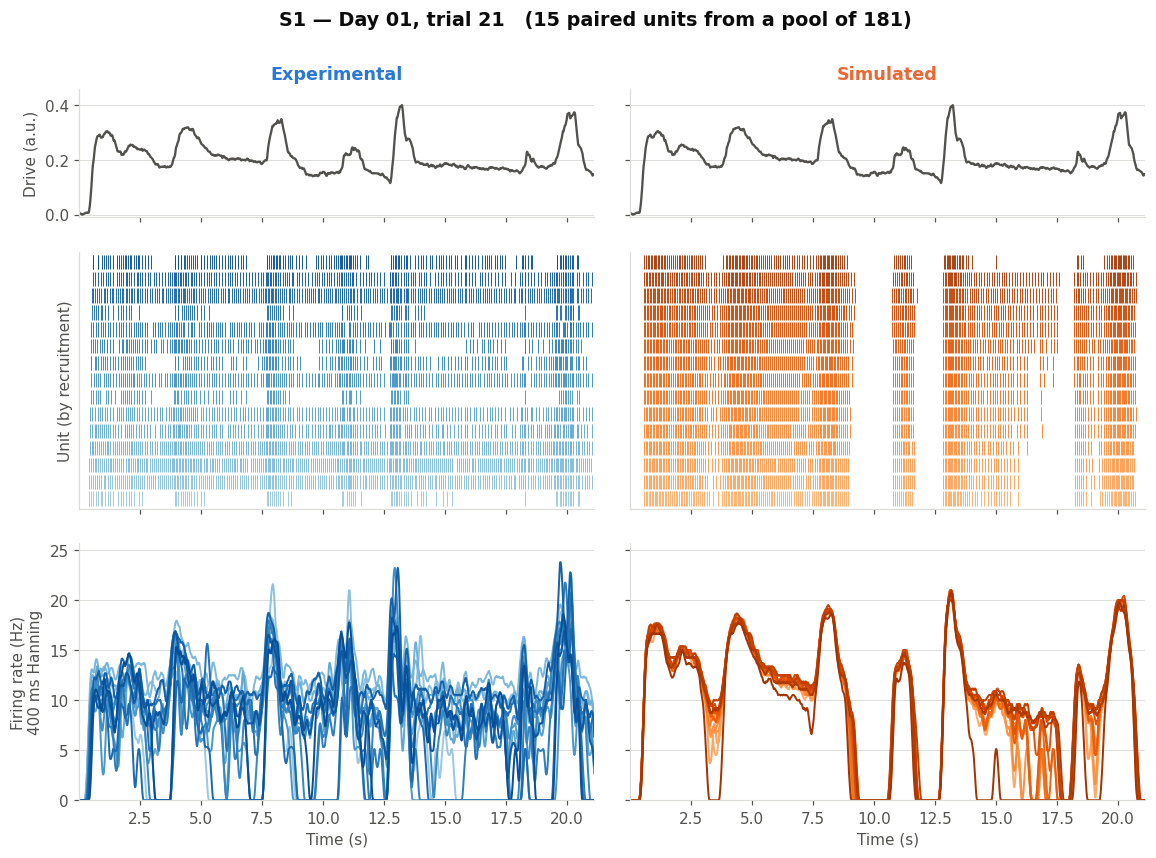

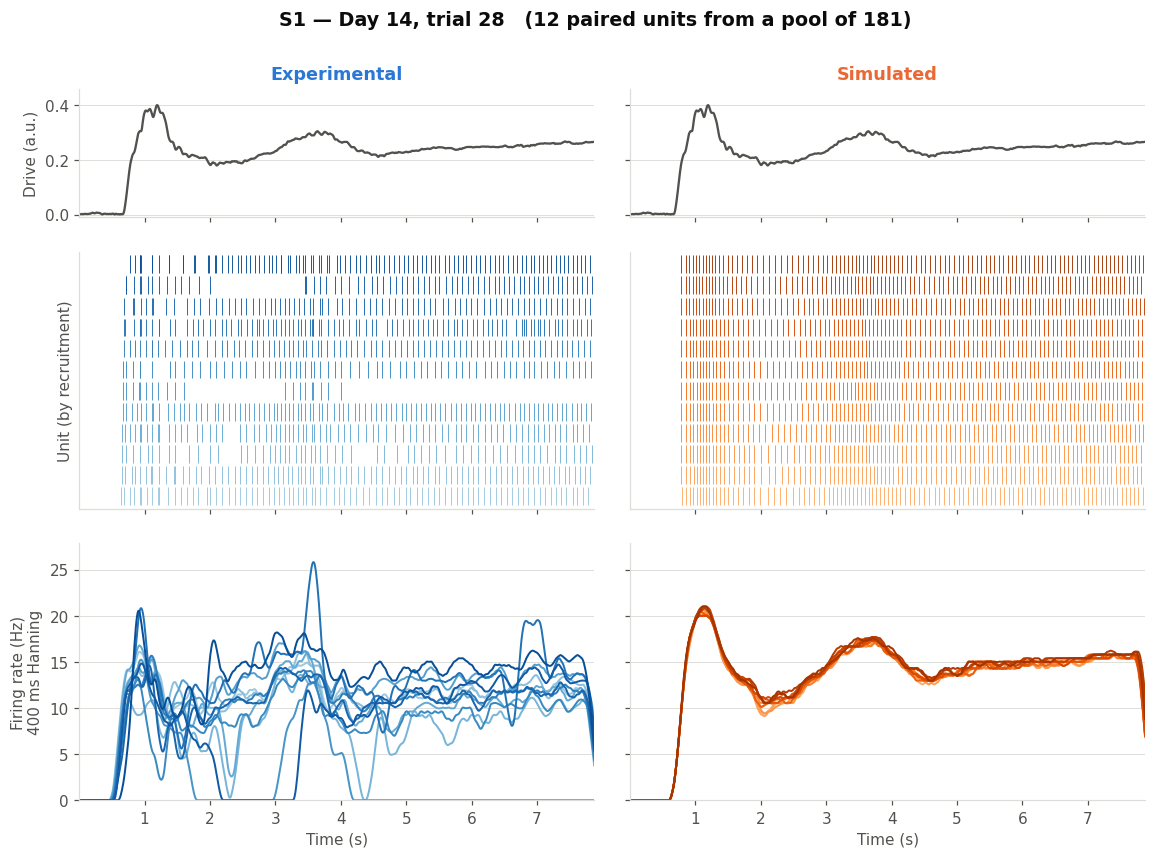

In [20]:
# An early and a late training day, if both have been simulated.
days_present = sorted({d for d, _ in available})
to_plot = [dt for dt in available if dt[0] in (days_present[:1] + days_present[-1:])]
for day, trial in to_plot:
    fr.plot_time_domain(day, trial, manifest, EXP_DIR, SIM_ROOT, SUBJECT,
                        SMOOTH_S, RATE_FS, MIN_SPIKES)
if not to_plot:
    print("No simulated trials yet -- run section 4, then re-run from here.")

### 7.4 What the comparison shows

Two features are reproduced and two are not.

**Reproduced.** Rate modulation tracks the drive: the peaks and troughs of the rate
traces fall where the force does.

**Not reproduced: the simulated units are far too synchronised.** In the right-hand rate
panels the traces lie almost exactly on top of one another, while the experimental units
in the left panel each follow their own course. The control in 7.2 puts a number on it —
shuffling the simulated partners barely changes the correlation, so the simulated units
are close to interchangeable. The mechanism is visible in `run_sim`:

```julia
full_input[i, :] = commoninput        # every motoneuron receives the identical input
```

and `simulate_trace` leaves `independantnoise` at zero. Units can differ only through
their intrinsic parameters, so they move as one. The repository already contains the
missing ingredient in `run_sim_noise.jl`, which adds a 50 Hz-filtered Gaussian noise term
per neuron — but nothing calls it.

**Not reproduced: de-recruitment is all-or-none.** Where the drive dips — 5–8 s on
Day 08, around 9 s and 12 s on Day 01 — the entire simulated pool falls silent together
and resumes together, while the recorded units keep discharging at 8–12 Hz throughout.
This follows from 3.1: the first unit recruits at 0.20 and enters at ~13 Hz, so when the
drive crosses that threshold there is no slow-firing regime to fall back to. The model
switches off instead of slowing down.

Both point at the input rather than at the scaling, and neither is visible in the
distributions of section 6.

**Limits of this comparison.** Pairing is by recruitment time, so the closeness of
`med_|d_recruit|_s` is a property of the matching, not a result. On several days the
recorded units are all already active when the trial begins — the experimental
recruitment span is 0.003 s on Day 04 and 0.17 s on Day 01 — so there is no recruitment
*sequence* to compare and the pairing on those days is close to arbitrary. And
decomposition does not sample the pool uniformly, so the paired subset is not a random
draw from the 181 simulated units.

---

## 8. Simulated units resembling the recorded ones

Section 7 asks whether experimental unit *i* has a simulated counterpart recruited at the
same moment, and 7.2 shows that pairing is weak. This section asks the question that fits
the data better: **does the pool contain units that behave like the ones that were
recorded?**

Decomposition recovers 11–17 units from a pool of 181, and it is not a uniform sample of
that pool — it favours units that are large and superficial enough to be separated. So
the useful comparison is not one-to-one over the whole pool, but whether the model's
repertoire includes the observed behaviour.

`up.match_units_by_similarity` assigns each experimental unit the simulated unit whose
smoothed rate trace is closest, minimising RMS difference in Hz so that a match agrees in
level as well as shape. Assignment is one-to-one and optimal over the full cost matrix.

**This is a best-of-181 selection, so it is biased in the model's favour by construction.**
With that many candidates the closest one is close whatever the model does. The informative
number is the margin over an arbitrary pairing, which the next cell reports alongside.

In [21]:
rng = np.random.default_rng(0)
rows, best_by_day = [], {}

for day, trial in available:
    tr, sim_spikes, sim_fs, _ = load_trial_pair(day, trial)
    if sim_spikes is None:
        continue
    best = up.match_units_by_similarity(tr.mu, tr.fs, sim_spikes, sim_fs,
                                        window_s=SMOOTH_S, target_fs=RATE_FS,
                                        criterion="rms", min_spikes=MIN_SPIKES)
    if best.empty:
        continue
    best_by_day[(day, trial)] = (tr, sim_spikes, sim_fs, best)

    # null: same experimental units against simulated partners drawn at random
    t_e, r_e = up.smoothed_rate(tr.mu, tr.fs, SMOOTH_S, RATE_FS)
    t_s, r_s = up.smoothed_rate(sim_spikes, sim_fs, SMOOTH_S, RATE_FS)
    n = min(len(t_e), len(t_s))
    pool = (up.recruitment_window(sim_spikes, sim_fs, MIN_SPIKES)
              .dropna(subset=["first_s"]).unit.to_numpy())
    draw = rng.permutation(pool)[:len(best)]
    null_rms = [np.sqrt(((r_e[a][:n] - r_s[b][:n]) ** 2).mean())
                for a, b in zip(best.exp_unit, draw)]

    rows.append({"day": day, "n_units": len(best),
                 "best_rms_hz": best.rms_hz.median(),
                 "random_rms_hz": np.median(null_rms),
                 "best_corr": best["corr"].median()})

similarity = pd.DataFrame(rows).set_index("day").round(2)
similarity["improvement"] = (similarity.random_rms_hz - similarity.best_rms_hz).round(2)
display(similarity)
print(f"\nmedian across days: best match {similarity.best_rms_hz.median():.2f} Hz RMS "
      f"vs {similarity.random_rms_hz.median():.2f} Hz for an arbitrary pairing "
      f"({similarity.improvement.median():+.2f} Hz)")
print(f"median correlation of the selected pairs: {similarity.best_corr.median():.2f}")

,n_units,best_rms_hz,random_rms_hz,best_corr,improvement
day,,,,,
1,15,3.75,6.34,0.66,2.59
3,11,5.68,7.93,0.63,2.25
4,14,5.33,8.15,0.57,2.82
5,13,5.68,7.74,0.71,2.06
6,10,3.81,6.77,0.75,2.96
7,17,3.05,7.67,0.79,4.62
8,14,4.48,7.97,0.53,3.49
9,15,4.24,7.60,0.63,3.36
10,16,3.03,9.18,0.66,6.15



median across days: best match 4.24 Hz RMS vs 7.74 Hz for an arbitrary pairing (+3.36 Hz)
median correlation of the selected pairs: 0.66


### 8.1 The closest-matching units

Each panel is one recorded unit and the simulated unit selected for it, over the whole
trial. Panels are ordered best match first, so the top row is the model at its most
convincing and the bottom row is where the resemblance runs out.

Day 10: median RMS 3.03 Hz


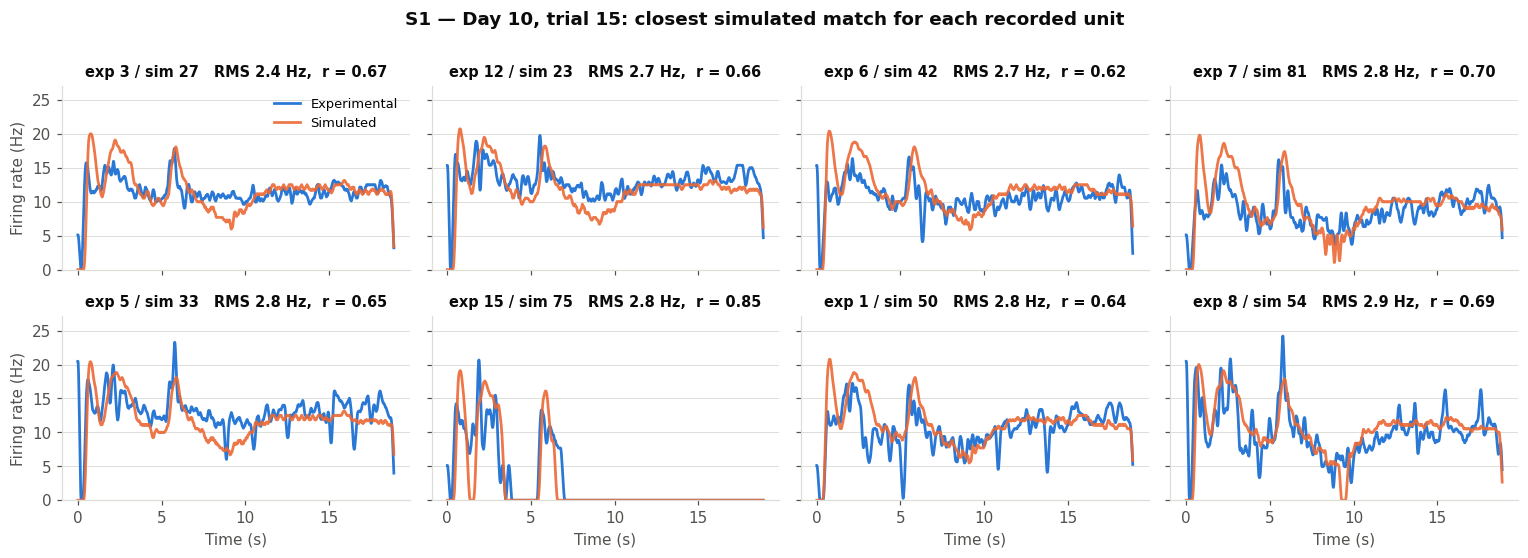

Day 05: median RMS 5.68 Hz


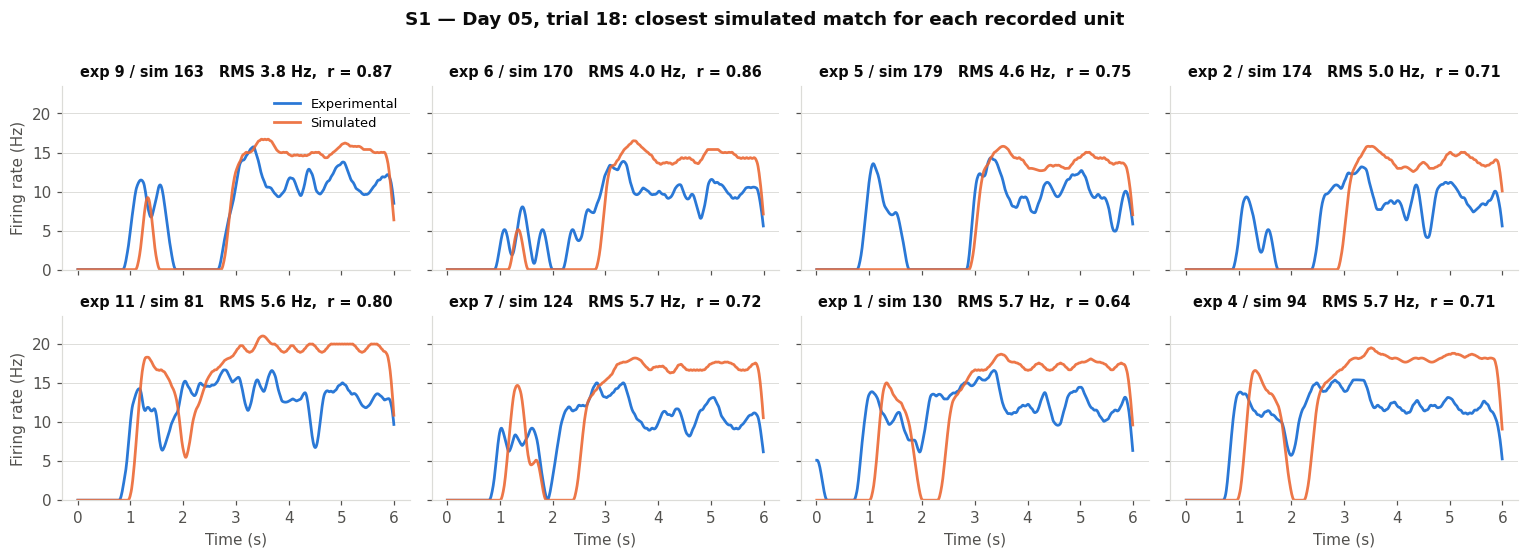

In [22]:
# the day whose units the model matches most closely, and the one it matches worst
if len(similarity):
    ordered = similarity.best_rms_hz.sort_values()
    for day in (ordered.index[0], ordered.index[-1]):
        trial = dict(available)[day]
        print(f"Day {day:02d}: median RMS {similarity.loc[day,'best_rms_hz']:.2f} Hz")
        fr.plot_best_matches(day, trial, best_by_day, SUBJECT, SMOOTH_S, RATE_FS)

---

## 9. Summary

The table in section 6 reports the shift in median firing rate for each day. Four things
bear on how it should be read.

1. **The model has a minimum sustained firing rate.** Section 3.1 measures it: units
   enter at a median of 13.3 Hz and there is no slow-firing regime near threshold. The
   simulated distribution therefore has no low tail, and part of the residual shift in
   section 6 is structural rather than a scaling error.

2. **Partial recruitment inflates the simulated upper tail.** Units recruited only near
   the force peak fire a single short burst, so all of their ISIs are short and the
   estimator returns a high rate. Setting `MIN_DUTY = 0.5` requires a unit to span at
   least half the trial and tests this directly.

3. **The pool and the recorded sample are different populations.** The simulation reports
   every motoneuron in the pool; decomposition returns 11–17 units per trial and is not a
   uniform sample of it. Matching on recruitment threshold, or restricting the comparison
   to the task-controlled pair (`Trial.pair`, from `Idx_MU_Pair`), is the sharper test.

4. **The scaling policy is part of the result.** `global_max` and `per_trial_max` deliver
   different recruitment, so state which one a figure used.

Sections 7 and 8 add the time-domain comparison, which locates the largest discrepancy: every
motoneuron receives an identical input, so the simulated pool discharges in near-unison
where the recorded units vary independently.